# 바톤 — 공공데이터 전처리·탐색 노트북

발달장애인 **돌봄 인계 플랫폼 ‘바톤’**에 들어가는 데이터를 원자료에서 어떻게 만들었는지 보여 주는 노트북입니다.

| 원자료 | 전처리 결과 |
|---|---|
| 2025 장애인복지시설 일람표(PDF, 2024.12 기준) | 거주시설 1,524곳·주간이용시설 855곳 시설 단위 표, 총괄표 대조 |
| 2025 국민기초생활보장 사업안내(PDF) | 기준 중위소득, 급여 선정기준, 보장시설 생계급여 기준, 규정 발췌(쪽수) |
| 시군구별 등록장애인수(CSV, 2025) | 시군구 결합 키를 붙인 수요 표 |
| 특광역시 장애인거주시설 현황(xlsx, 2020~2025) | 연도 × 지역 × 시설유형 긴 형식 |
| 장애수당(기초생활보장) 수급자(ZIP, 2025.12~2026.9) | 월별 통합 표 — 검토 후 서비스 지표에서는 제외 |
| 사회복지시설정보 OpenAPI | `src/fetch_facility_api.py` 실행 후 채워짐 |

> 다시 실행하려면 위쪽의 **Run All**을 누르세요. 먼저 `python src/run_all.py` 로 전처리 결과를 만들어 두어야 합니다.

In [1]:
import sys, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
from common import PROCESSED, API_DIR, setup_korean_font, RES_TYPE_NAME, SIDO_ORDER
setup_korean_font()
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 200)
print('전처리 폴더:', PROCESSED)

전처리 폴더: C:\Users\서윤\Desktop\사회보장\baton_project\data\processed


## 1. 일람표 PDF → 시설 단위 표
시설 목록에서 뽑은 값을 같은 문서 3쪽 총괄표(시도 17 × 종류 8 × 시설수·정원·현원 = 408칸)와 맞춰 봅니다.

In [2]:
res = pd.read_csv(PROCESSED / 'residential_facilities.csv')
val = pd.read_csv(PROCESSED / 'ilam_validation.csv')
print(f"거주시설 {len(res):,}곳 | 정원 {res['입소정원'].sum():,} | 현원 {res['입소현원'].sum():,} | 빈자리 {res['빈자리'].sum():,}")
print(f"총괄표 대조: {val['일치'].sum()} / {len(val)} 칸 일치")
res.head(8)

거주시설 1,524곳 | 정원 31,229 | 현원 26,987 | 빈자리 4,242
총괄표 대조: 408 / 408 칸 일치


,소관시도,시설종류,pdf_page,일련번호,소관시군구,시설명,입소정원,입소현원,종사자정원,종사자현원,소재지주소,설치신고일,법인명,빈자리,소재지시도
0,서울,지체,13,1,강동구,주몽재활원,40,37,39,38,서울특별시 강동구 상암로369(상일동),1985-04-11,사회복지법인 주몽재단,3,서울
1,서울,지체,13,2,관악구,에스알씨(SRC)보듬터,40,32,36,31,경기도 광주시 초월읍 경수길 25,1952-06-12,사회복지법인SRC,8,경기
2,서울,시각,13,1,강북구,한빛맹아원,55,52,42,42,서울특별시 강북구 삼양로 73가길 59,1968-09-26,사회복지법인 한빛재단,3,서울
3,서울,시각,13,2,노원구,대린원,54,29,27,30,서울특별시 노원구 동일로248길 30,1973-06-25,홍파복지원,25,서울
4,서울,시각,13,3,서초구,새빛바울의집,33,17,21,19,서울특별시 서초구 방배중앙로 99,2005-04-14,사복 새빛복지재단,16,서울
5,서울,청각,13,1,동작구,삼성농아원,35,23,26,26,서울특별시 동작구 양녕로 30길19-4,1957-03-02,서울삼성원,12,서울
6,서울,지적,14,1,강동구,사랑쉼터의집,29,20,26,6,서울특별시 강동구 상암로 79길 24,2007-11-16,개인,9,서울
7,서울,지적,14,2,강동구,우성원,56,56,47,46,서울특별시 강동구 고덕로 295-45,1979-05-28,우성재단,0,서울


In [3]:
g = res.groupby('시설종류').agg(시설수=('시설명','size'), 정원=('입소정원','sum'), 현원=('입소현원','sum'),
                             종사자정원=('종사자정원','sum'), 종사자현원=('종사자현원','sum'))
g['빈자리'] = g['정원'] - g['현원']; g['빈자리율(%)'] = (g['빈자리']/g['정원']*100).round(1)
g['종사자충원율(%)'] = (g['종사자현원']/g['종사자정원']*100).round(1)
g.index = [RES_TYPE_NAME[t] for t in g.index]
g.sort_values('정원', ascending=False)

,시설수,정원,현원,종사자정원,종사자현원,빈자리,빈자리율(%),종사자충원율(%)
지적장애인 거주시설,307,11957,10586,8426,7761,1371,11.5,92.1
중증장애인 거주시설,251,11537,10057,9083,8381,1480,12.8,92.3
장애인 공동생활가정,742,3119,2758,1245,1188,361,11.6,95.4
장애인 단기거주시설,168,2101,1719,1694,1451,382,18.2,85.7
지체장애인 거주시설,25,1002,843,715,672,159,15.9,94.0
시각장애인 거주시설,15,750,550,447,437,200,26.7,97.8
장애영유아 거주시설,9,427,310,361,308,117,27.4,85.3
청각·언어장애인 거주시설,7,336,164,150,142,172,51.2,94.7


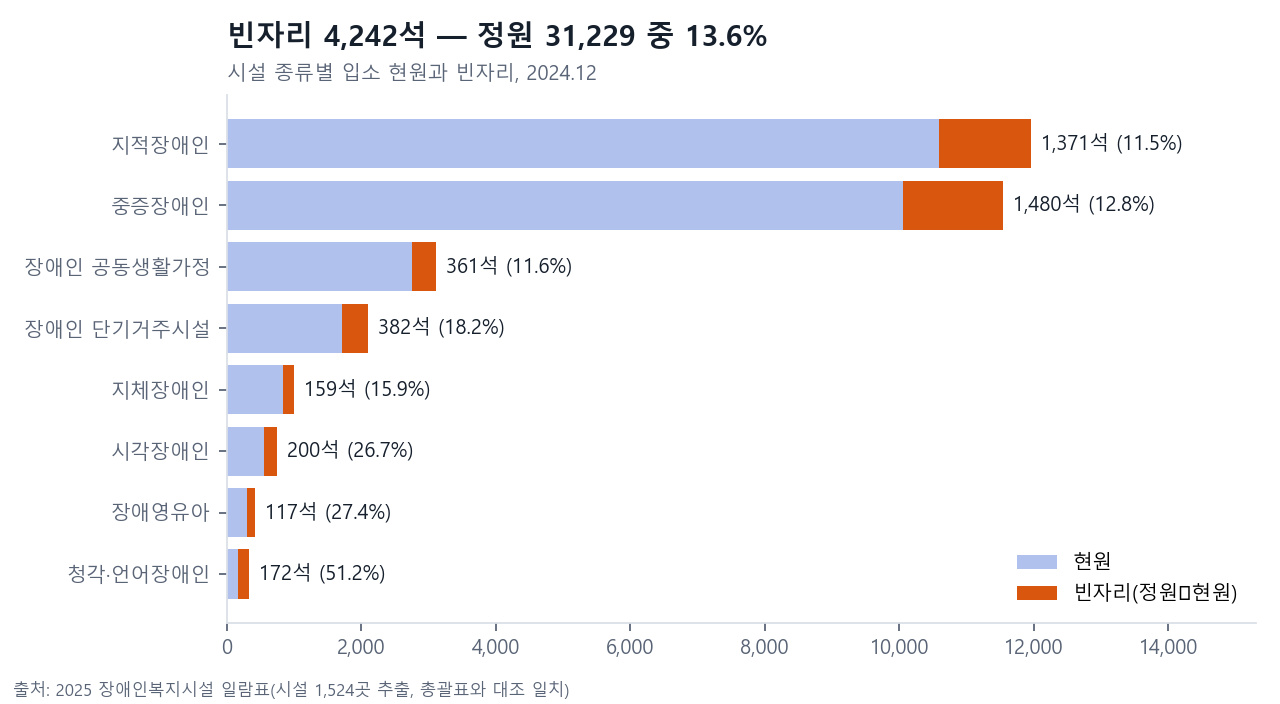

In [4]:
from IPython.display import Image, display
display(Image(filename=str(ROOT/'outputs/figures/fig02_vacancy_by_type.png')))

## 2. 주간이용시설(낮 돌봄)
일람표 3장 지역사회재활시설 중 ‘장애인 주간이용시설’ 표를 뽑아 4쪽 총괄표의 시도별 개수와 맞춥니다.

In [5]:
day = pd.read_csv(PROCESSED / 'day_facilities.csv')
com = pd.read_csv(PROCESSED / 'ilam_summary_community.csv').set_index('시도')
chk = day.groupby('소관시도').size().rename('목록').to_frame().join(com['주간이용시설'].rename('총괄표'))
chk['일치'] = chk['목록'] == chk['총괄표']
print(f"주간이용시설 {len(day)}곳, 시도별 일치 {chk['일치'].sum()}/{len(chk)}")
chk.T

주간이용시설 855곳, 시도별 일치 17/17


소관시도,강원,경기,경남,경북,광주,대구,대전,부산,서울,세종,울산,인천,전남,전북,제주,충남,충북
목록,20,159,52,55,39,53,48,67,134,3,42,42,29,34,32,19,27
총괄표,20,159,52,55,39,53,48,67,134,3,42,42,29,34,32,19,27
일치,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True


## 3. 거주시설 추이(xlsx)

In [6]:
t = pd.read_csv(PROCESSED / 'residential_trend_2020_2025.csv')
t[(t['지역']=='전국')].pivot_table(index='시설유형', columns='연도', values='값', aggfunc='sum').loc[:, :]

연도,2020,2021,2022,2023,2024,2025
시설유형,,,,,,
공동생활가정,3626,3576,3564,3552,3500,3437
단기거주시설,1890,1956,2036,1902,1887,1902
시각장애인시설,595,584,577,572,565,562
장애 영유아 거주시설,370,366,341,333,319,324
중증장애인거주시설,11117,10817,10702,10472,10308,10139
지적장애인시설,11666,11515,11166,10997,10893,10778
지체장애인시설,1149,1083,908,874,868,860
청각·언어장애인시설,212,203,184,179,171,171
합계,30625,30100,29478,28881,28511,28173


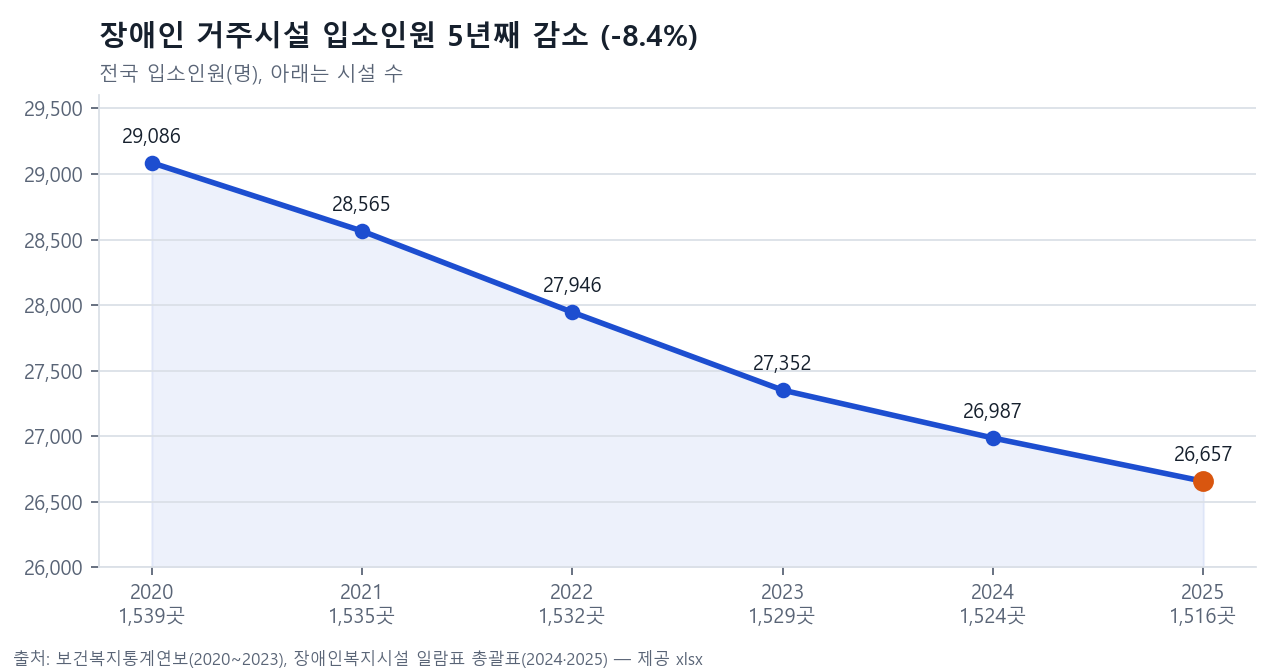

In [7]:
display(Image(filename=str(ROOT/'outputs/figures/fig01_residential_trend.png')))

## 4. 지역별 돌봄 공백 (일람표 + 등록장애인 결합)
시설의 시군구는 **소관** 기준이고, 수요 지표(심한 장애 등록장애인)는 모든 장애유형을 포함합니다.

In [8]:
sido = pd.read_csv(PROCESSED / 'region_sido_panel.csv')
sido[['시도','시설수','정원','현원','빈자리율(%)','종사자충원율(%)','심한장애','발달관련_정원','심한장애_1천명당_발달관련정원','단기거주없는_시군구','시군구수']]

,시도,시설수,정원,현원,빈자리율(%),종사자충원율(%),심한장애,발달관련_정원,심한장애_1천명당_발달관련정원,단기거주없는_시군구,시군구수
0,서울,248,3485,2920,16.2,90.5,140859,3133,22.2,6,25
1,부산,63,1351,1192,11.8,97.8,64874,1146,17.7,13,16
2,대구,52,1681,1313,21.9,95.8,46507,1631,35.1,7,9
3,인천,69,1054,904,14.2,93.4,54437,846,15.5,6,10
4,광주,80,1002,927,7.5,97.1,27559,912,33.1,2,5
5,대전,81,1396,1187,15.0,84.6,27953,1256,44.9,0,5
6,울산,28,725,638,12.0,95.9,18923,670,35.4,0,5
7,세종,7,166,159,4.2,82.2,5013,166,33.1,1,1
8,경기,317,6223,5367,13.8,92.5,215104,5822,27.1,10,31
9,강원,69,1655,1425,13.9,88.6,36441,1575,43.2,13,18


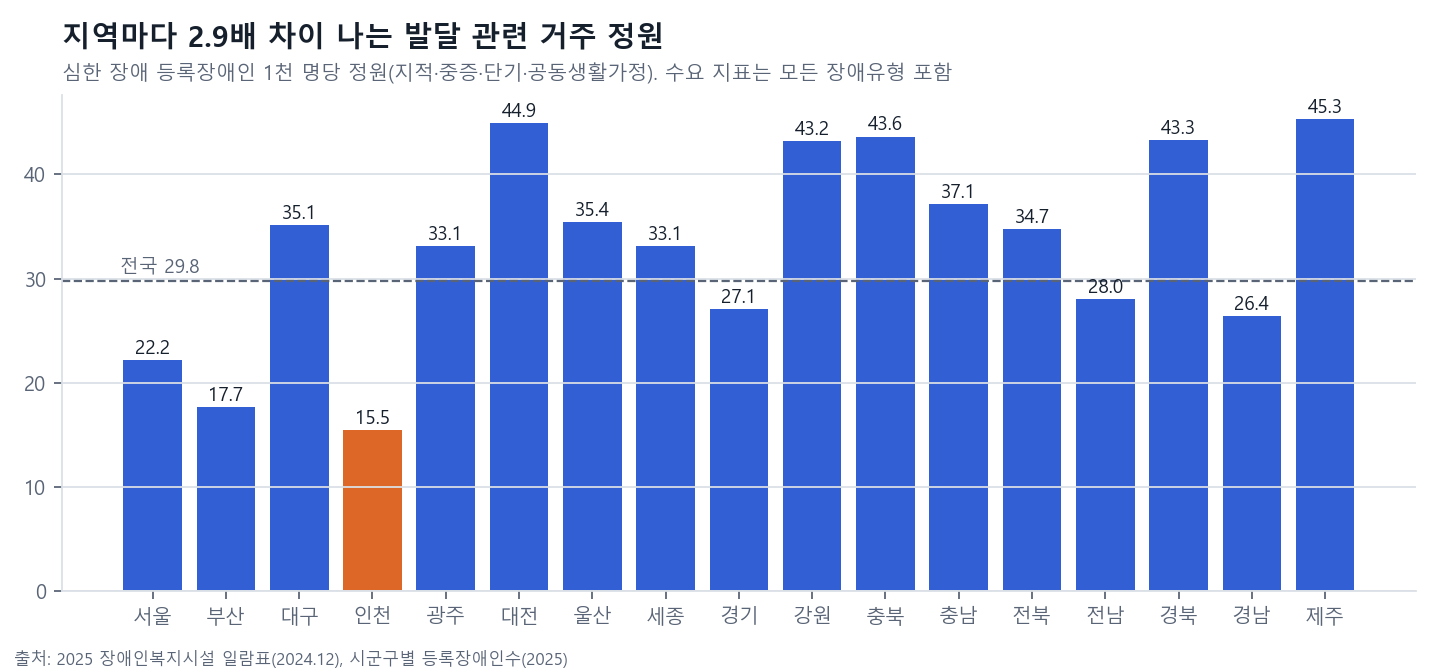

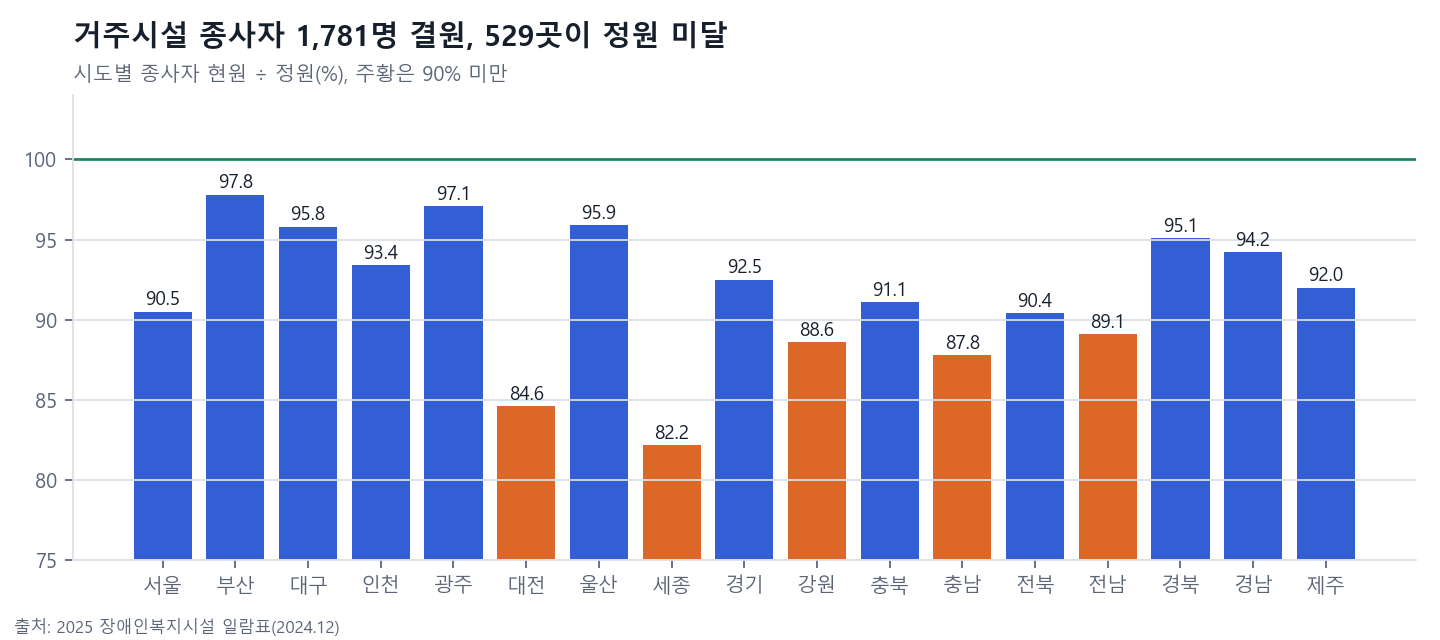

In [9]:
display(Image(filename=str(ROOT/'outputs/figures/fig03_supply_per_1000_severe.png')))
display(Image(filename=str(ROOT/'outputs/figures/fig04_staff_fill_rate.png')))

In [10]:
p = pd.read_csv(PROCESSED / 'region_sgg_panel.csv')
print(f"단기거주시설 없는 시군구: {p['단기거주_없음'].sum()} / {len(p)}  (심한 장애 {p.loc[p['단기거주_없음'],'심한장애'].sum():,}명)")
print(f"단기거주·주간이용 둘 다 없는 시군구: {(p['단기거주_없음'] & p['주간이용_없음']).sum()}")
p[p['단기거주_없음']].sort_values('심한장애', ascending=False)[['시도','시군구키','심한장애','주간이용시설_수','장기거주(지적·중증)_시설수','공동_시설수']].head(15)

단기거주시설 없는 시군구: 129 / 229  (심한 장애 344,307명)
단기거주·주간이용 둘 다 없는 시군구: 35


,시도,시군구키,심한장애,주간이용시설_수,장기거주(지적·중증)_시설수,공동_시설수
40,경기,용인시,13933,9,10,11
157,인천,남동구,9859,7,1,2
52,경남,김해시,9728,5,4,3
161,인천,서구,9603,5,0,9
98,대구,동구,7323,8,7,4
128,서울,관악구,6893,5,1,6
117,부산,사하구,6745,7,0,9
101,대구,수성구,6608,8,3,4
123,부산,해운대구,6467,6,3,1
212,충남,아산시,6334,3,5,0


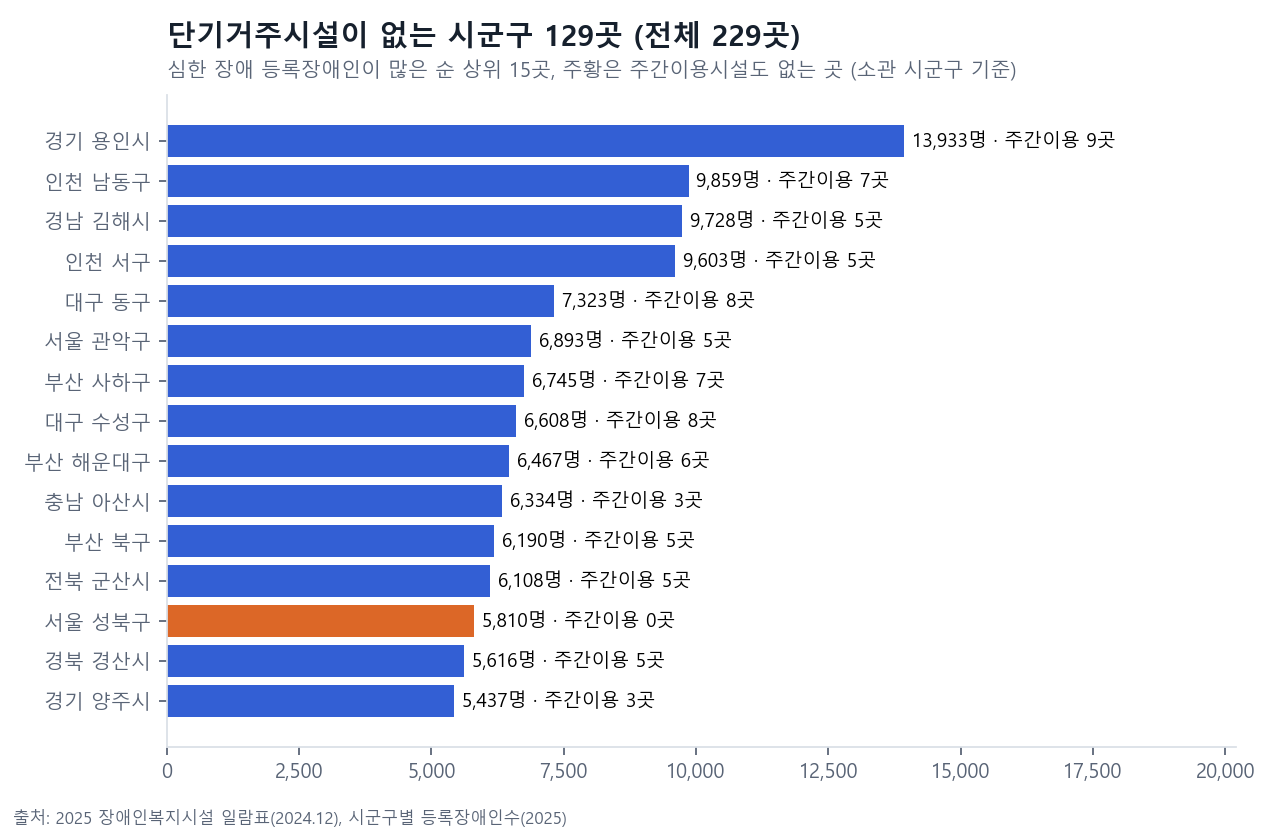

In [11]:
display(Image(filename=str(ROOT/'outputs/figures/fig05_no_short_stay_sgg.png')))

## 5. 국민기초생활보장 사업안내 PDF → 기준값·규정
규정 문장은 원문에서 찾아 **인쇄 쪽수**와 함께 저장합니다(서비스 화면의 근거 표기에 사용).

In [12]:
pd.read_csv(PROCESSED / 'nblsa_selection_criteria_2025.csv').pivot(index='급여', columns='가구원수', values='선정기준_원')

가구원수,1,2,3,4,5,6,7
급여,,,,,,,
교육급여,1196007,1966329,2512677,3048887,3554096,4032403,4494214
생계급여,765444,1258451,1608113,1951287,2274621,2580738,2876297
의료급여,956805,1573063,2010141,2439109,2843277,3225922,3595371
주거급여,1148166,1887676,2412169,2926931,3411932,3871106,4314445


In [13]:
pd.read_csv(PROCESSED / 'nblsa_facility_benefit_2025.csv')

,수급자현원_구간,월급여액_원,출처
0,30인 미만,356568,2025 국민기초생활보장 사업안내 338쪽(PDF 363쪽)
1,30인 이상~100인 미만,323664,2025 국민기초생활보장 사업안내 338쪽(PDF 363쪽)
2,100인 이상~300인 미만,311162,2025 국민기초생활보장 사업안내 338쪽(PDF 363쪽)
3,300인 이상,311139,2025 국민기초생활보장 사업안내 338쪽(PDF 363쪽)


In [14]:
pd.set_option('display.max_colwidth', 120)
pd.read_csv(PROCESSED / 'nblsa_rules.csv')[['설명','인쇄쪽','원문발췌']]

,설명,인쇄쪽,원문발췌
0,"발달장애인 등 의사무능력자는 후견인 지정을 우선 검토, 공공후견지원사업 이용",283,"판단되는 경우 민법상 후견인(부록 Ⅶ 성년후견제도 참조)을 지정하여 급여관리가 될 수 있도록 우선 검토 ※ 필요시 발달장애인, 치매환자, 정신질환자 공공후견지원사업 이용 ○ 후견인 지정이 어렵거나, 후견인 지정까지 상당한 시간이 소요되는 경우 예외적으로 급여관리자를 지정하여 급여를 대신 관리하도록 할 수 있으며"
1,후견인 지정이 어렵거나 오래 걸리면 급여관리자를 지정해 급여를 대신 관리,283,"공공후견지원사업 이용 ○ 후견인 지정이 어렵거나, 후견인 지정까지 상당한 시간이 소요되는 경우 예외적으로 급여관리자를 지정하여 급여를 대신 관리하도록 할 수 있으며, 타인에 의한 수급권 침해를 사전 예방하기 위해 반기 또는 연 1회 확인･점검 실시 ※ 후견인이 지정된 경우 급여관리 및 점검 불필요 ○ 다만"
2,장애인공동생활가정은 사회복지시설이지만 보장시설은 아님,319,"되지 않으면 보장시설이 아니며 동 시설 수급자는 보장시설 수급자가 아닌 일반 수급자에 해당 ※ 예를 들어, 장애인공동생활가정은 「사회복지사업법」상 사회복지시설이나 보장시설은 아님 ○ 이와 관련하여 「국민기초생활 보장법」에서는 보건복지부장관과 시･도지사는 수급자를 각각 국가 또는 당해 지방자치단체가 운영하는 보장시설에 입"
3,보장시설 요건: 정부로부터 운영비와 인건비를 전액 지원받는 생활시설,320,"조, 시행규칙 제41조의3] (1) 보장시설의 요건 ○ 「사회복지사업법」에 따른 사회복지시설(생활시설)로서 정부로부터 운영비와 인건비를 전액 지원받는 시설 ※ 운영주체가 개인이거나 정부로부터 운영비와 인건비를 전액 지원받는 시설이 아닌 경우에는 “정부 지원을 받지 못하"
4,"장애인거주시설은 보장시설(장애인단기거주시설, 장애인공동생활가정 제외)",320,"설 종 류 특 성 ⦁장애인거주시설(장애인단기 1. 장애인복지시설 ⦁장애인에 대한 거주･요양･지원 등 서비스 거주시설, 장애인공동생활 (장애인복지법 제58조) 제공 및 지역사회생활 지원 가정 제외) ⦁노인을 입소시켜 급식과 그 밖에 일상생활 ⦁양로시설 편의 제공 ⦁가정과 같은"
5,보장시설은 위탁받은 급여를 정당한 사유 없이 거부할 수 없고 위반 시 300만원 이하 벌금 등,323,"6조제3항 및 제4항] 나. 급여 위탁 관련 의무 ○ 보장기관으로부터 수급자에 대한 급여를 위탁받은 때에는 정당한 사유 없이 거부할 수 없고, 이를 위반하면 300만원 이하의 벌금, 구류 또는 과료에 처함 [법 제33조, 제50조] ○ 보장기관은 보건복지부장관이 정하는 바에 따라 정"
6,"보장시설 수급자는 별도 보장가구, 남은 가구원은 부양의무자로 처리",324,"야 함 ○ 보장시설 수급자로 보장시 유의사항 ‑ 보장시설 입소자는 주민등록을 보장기관으로 변경하여야 함 ‑ 보장시설 수급자는 별도 보장가구로 인정하여 급여를 지급하는 대상에 해당되므로 가구 구성원에서 제외함. 즉, 보장시설 수급자로 선정되기 전의 나머지 가구원은 배우자를 포함하여 모두 부양의"
7,보장시설 입소자는 주민등록을 보장기관으로 변경,324,"곳에서는 급여의 목적을 달성할 수 없거나, 본인이 희망하여야 함 ○ 보장시설 수급자로 보장시 유의사항 ‑ 보장시설 입소자는 주민등록을 보장기관으로 변경하여야 함 ‑ 보장시설 수급자는 별도 보장가구로 인정하여 급여를 지급하는 대상에 해당되므로 가구 구성원에서 제외함. 즉, 보장시설 수급자로 선정되기 전의"
8,장애인시설 등에서 퇴소해 부양의무자가 부양을 거부·기피하면 지방생활보장위원회로 보장 필요성 검토,325,"보장이 필요하다고 인정되는 자에 대해서는 지방생활보장위원회의 심의･의결을 거쳐 보장할 수 있음 ※ 특히, 장애인시설 등에서 퇴소하여 부양의무자가 부양을 거부하거나 기피하는 경우 지방생활보장 위원회를 통하여 보장 필요성 검토 1) 부양의무자의 부양능력 판정기준 완화(의료급여만 적용) ○ 부양능력 판정소득액과 재산의 소득"
9,수급자가 아닌 사람이 보장시설에 입소했다는 이유만으로는 수급자격이 생기지 않음,333,"자로 선정된 자에 한하여 생계급여를 지급해야 함 ‑ 생계급여 또는 의료급여 수급자가 아닌 사람이 보장시설에 입소하였다는 이유만으로는 수급자격 요건을 만족할 수 없으며, 제2편 신청 및 선정기준, 제3편 조사, 제6편 보장시설에 따른 절차를 거쳐 생계급여 또는 의료급여 수급자로 선정되"


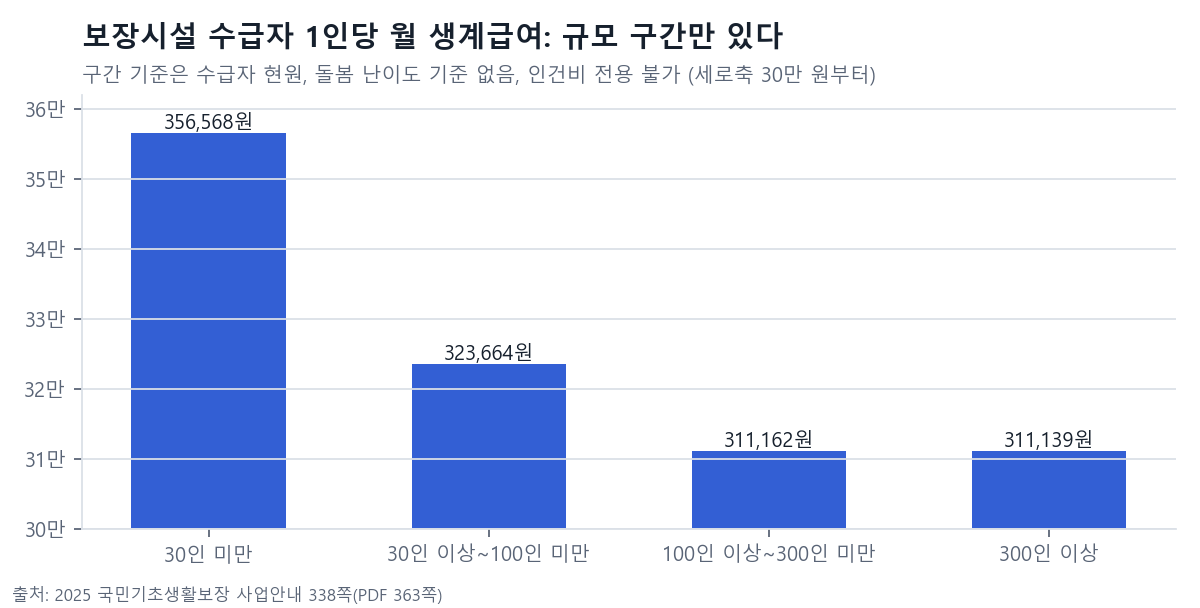

In [15]:
display(Image(filename=str(ROOT/'outputs/figures/fig06_facility_benefit_tiers.png')))

## 6. 장애수당(기초생활보장) 수급자 — 검토 후 제외한 이유

자폐성 장애인은 대부분 장애인연금 대상이라 이 자료에 거의 잡히지 않아, 발달장애 수요 지표로 쓰지 않았습니다.


,합계,지적,자폐성
통계연월,,,
202512,310589,29016,285
202601,312427,29255,296
202602,311509,29234,297
202603,315429,29708,310
202604,317549,29871,318
202605,319173,30003,324
202606,320746,30146,332
202607,322240,30312,337
202608,323656,30441,340


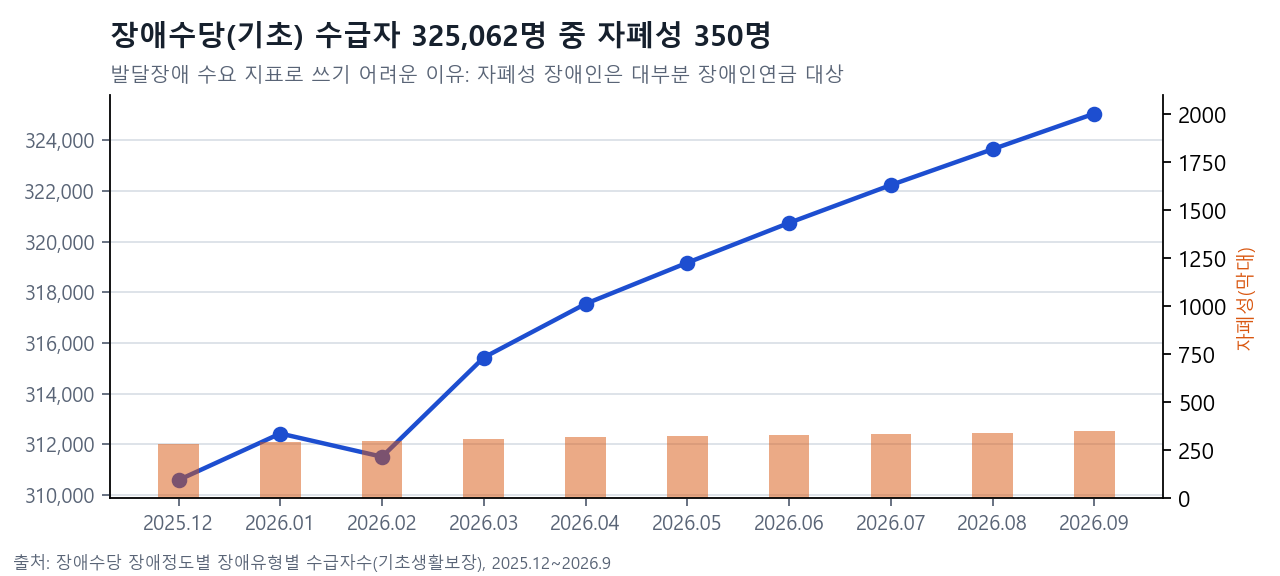

In [16]:
m_path = PROCESSED / 'allowance_basic_monthly.csv'
if m_path.exists():
    m = pd.read_csv(m_path, index_col=0)
    print('자폐성 장애인은 대부분 장애인연금 대상이라 이 자료에 거의 잡히지 않아, 발달장애 수요 지표로 쓰지 않았습니다.')
    display(m[['합계','지적','자폐성']])
    display(Image(filename=str(ROOT/'outputs/figures/fig08_allowance_review.png')))
else:
    print('장애수당 ZIP 파일이 원자료 폴더에 없어 건너뜁니다.')

## 7. 사회복지시설정보 OpenAPI
`python src/fetch_facility_api.py` 로 수집하면 아래 셀이 채워집니다. 인터넷 없이 형식만 확인하려면 `--mock` 옵션을 쓰세요.

In [17]:
f = API_DIR / 'api_facilities.csv'
if f.exists():
    api = pd.read_csv(f, dtype=str)
    print(f"API 장애인 관련 시설 {len(api):,}곳")
    display(api.head())
    jp = API_DIR / 'api_jobs.csv'
    if jp.exists(): print(f"구인 공고 {len(pd.read_csv(jp)):,}건")
    rp = PROCESSED / 'facility_api_match_report.csv'
    if rp.exists(): display(pd.read_csv(rp))
else:
    mock = API_DIR / 'mock' / 'api_facilities.csv'
    print('아직 실제 API 수집 전입니다.' + (' 모의 실행 결과:' if mock.exists() else ''))
    if mock.exists(): display(pd.read_csv(mock, dtype=str))

API 장애인 관련 시설 2,384곳
구인 공고 229건


,fcltNm,fcltCd,fcltKindNm,fcltKindCd,jrsdSggCd,jrsdSggNm,rprsNm,srvInstId,요청_종류코드,종류상세명,바톤단계
0,본미소힐링센터,C8324,장애인거주시설,030107,2729000000,대구광역시 달서구,이OO,C0118790355,030107,장애인단기거주시설,단기거주
1,해늘단기보호센터,C0905,장애인거주시설,030107,2823700000,인천광역시 부평구,한OO,C0000030791,030107,장애인단기거주시설,단기거주
2,들꽃단기보호시설,C8054,장애인거주시설,030107,2653000000,부산광역시 사상구,조OO,C0109007820,030107,장애인단기거주시설,단기거주
3,연수허브 단기보호센터,C6753,장애인거주시설,030107,2818500000,인천광역시 연수구,임OO,C0000030284,030107,장애인단기거주시설,단기거주
4,승담단기거주시설,C9716,장애인거주시설,030107,5011000000,제주특별자치도 제주시,오OO,C0294570219,030107,장애인단기거주시설,단기거주


,시설종류,일람표시설,API매칭,매칭률(%)
0,공동,789,627,79.5
1,단기,175,154,88.0
2,시각,15,13,86.7
3,영유아,9,9,100.0
4,주간이용,864,599,69.3
5,중증,261,246,94.3
6,지적,321,272,84.7
7,지체,25,20,80.0
8,청각,7,6,85.7
